# Proyecto IA: Brecha Digital y Rendimiento Escolar en el Perú (2025)
**Estudiante:** Puma Condori Julmer | **Curso:** Inteligencia Artificial | **Escuela:** Ingeniería de Sistemas

---

## 1. Configuración del Entorno e Importación de Librerías
**Objetivo:** Preparar el entorno de trabajo importando las bibliotecas necesarias para manipulación de datos, modelado, métricas y explicabilidad.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning & Scaling
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

# Advanced ML & XAI
from lightgbm import LGBMClassifier
import shap
from simpledbf import Dbf5

PyTables is not installed. No support for HDF output.
SQLalchemy is not installed. No support for SQL output.


---

## 2. Ingesta y Limpieza de Microdatos ENAHO (Fase 1)
**Objetivo:** Extraer de forma segura los datos de ENAHO, preservando ceros a la izquierda en los identificadores espaciales e imputando correctamente los valores nulos leídos como espacios.

**Procedimiento:** Se define una función de carga adaptada para extraer exclusivamente la data de 2025 desde los archivos panel, mapeando las variables de interés (incluyendo `P300A` para Lengua Materna y `P208A` para edad).

In [3]:
# 1. Definir llaves protegiendo los ceros (prevención de pérdida de códigos geográficos)
llaves_str_25 = {
    'aÑo_25': str, 'mes_25': str, 'conglome_25': str,
    'vivienda_25': str, 'hogar_25': str, 'codperso_25': str, 'ubigeo_25': str
}

# 2. Función maestra de extracción segura
def cargar_2025_desde_panel(ruta, columnas_25):
    df = pd.read_csv(
        ruta,
        dtype=llaves_str_25,
        encoding='latin1',
        na_values=['', ' '], # Manejar celdas vacías del INEI
        usecols=lambda c: c.lower() in columnas_25
    )
    # Estandarización de nombres: quitar sufijo y pasar a mayúsculas
    df.columns = df.columns.str.lower().str.replace(r'_25$', '', regex=True).str.upper()
    df = df.dropna(subset=['CONGLOME', 'VIVIENDA', 'HOGAR'])
    
    # Limpieza de espacios en llaves primarias
    for col in ['CONGLOME', 'VIVIENDA', 'HOGAR', 'UBIGEO']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.zfill(6 if col == 'UBIGEO' else 4)
            
    return df

# 3. Definición de variables requeridas por módulo
cols_100_25 = ['aÑo_25', 'conglome_25', 'vivienda_25', 'hogar_25', 'ubigeo_25', 'estrato_25']
cols_200_25 = ['aÑo_25', 'conglome_25', 'vivienda_25', 'hogar_25', 'codperso_25', 'p203_25', 'p207_25', 'p208a_25']
cols_300_25 = ['aÑo_25', 'conglome_25', 'vivienda_25', 'hogar_25', 'codperso_25', 'p300a_25', 'p306_25', 'p307_25', 'p314a_25']
cols_sum_25 = ['aÑo_25', 'conglome_25', 'vivienda_25', 'hogar_25', 'pobreza_25', 'inghog2d_25', 'gashog2d_25', 'factor07_25']

# 4. Carga de DataFrames
df_100 = cargar_2025_desde_panel('enaho01-2021-2025-100-panel.csv', cols_100_25)
df_200 = cargar_2025_desde_panel('enaho01-2021-2025-200-panel.csv', cols_200_25)
df_300 = cargar_2025_desde_panel('enaho01a-2021-2025-300-panel.csv', cols_300_25)
df_sumaria = cargar_2025_desde_panel('sumaria-2021-2025-panel.csv', cols_sum_25)

# 5. Aislamiento estricto de Población en Edad Escolar (6 a 17 años)
df_200['P208A'] = pd.to_numeric(df_200['P208A'], errors='coerce')
df_200_escolar = df_200[(df_200['P208A'] >= 6) & (df_200['P208A'] <= 17)].copy()

print(f"Población escolar identificada (6-17 años): {len(df_200_escolar)} registros.")

Población escolar identificada (6-17 años): 24195 registros.


---

## 3. Integración de Datos Educativos MINEDU - ESCALE
**Objetivo:** Agregar características distritales de infraestructura educativa y cruzar la información sin pérdida de datos.

In [4]:
# 1. Leer Padron DBF
dbf = Dbf5('Padron.dbf', codec='latin1')
df_padron = dbf.to_dataframe()

# Conservar y limpiar UBIGEO
df_padron['CODGEO'] = df_padron['CODGEO'].astype(str).str.strip().str.zfill(6)

# Asegurar variables numéricas para agrupación
df_padron['TALUM'] = pd.to_numeric(df_padron['TALUM'], errors='coerce').fillna(0)
df_padron['TDOC'] = pd.to_numeric(df_padron['TDOC'], errors='coerce').fillna(0)

# 2. Agrupación distrital y prevención de división por cero
df_distrito = df_padron.groupby('CODGEO').agg(
    TOTAL_ALUMNOS=('TALUM', 'sum'),
    TOTAL_DOCENTES=('TDOC', 'sum')
).reset_index()

df_distrito['RATIO_ALUMNO_DOCENTE'] = np.where(
    df_distrito['TOTAL_DOCENTES'] > 0,
    df_distrito['TOTAL_ALUMNOS'] / df_distrito['TOTAL_DOCENTES'],
    0
)
df_distrito = df_distrito.rename(columns={'CODGEO': 'UBIGEO'})

# 3. Cruce Relacional Maestro (Merge)
llaves_persona = ['CONGLOME', 'VIVIENDA', 'HOGAR', 'CODPERSO']
llaves_hogar = ['CONGLOME', 'VIVIENDA', 'HOGAR']

df_master = pd.merge(df_200_escolar, df_300, on=llaves_persona, how='inner')
df_master = pd.merge(df_master, df_100, on=llaves_hogar, how='left')
df_master = pd.merge(df_master, df_sumaria, on=llaves_hogar, how='left')
df_master = pd.merge(df_master, df_distrito, on='UBIGEO', how='left')

# Ingeniería de variables cualitativas solicitadas por la guía (Lengua Originaria)
# P300A: 4=Quechua, 5=Aymara, 6=Otra lengua nativa
df_master['P300A'] = pd.to_numeric(df_master['P300A'], errors='coerce')
df_master['LENGUA_ORIGINARIA'] = np.where(df_master['P300A'].isin([4, 5, 6]), 1, 0)

print("Dimensión de la base final (Filas, Columnas):", df_master.shape)

Dimensión de la base final (Filas, Columnas): (23668, 21)


---

## 4. Análisis Exploratorio de Datos (EDA)
**Objetivo:** Comprender la distribución socioeconómica de los estudiantes y la prevalencia de la brecha digital.

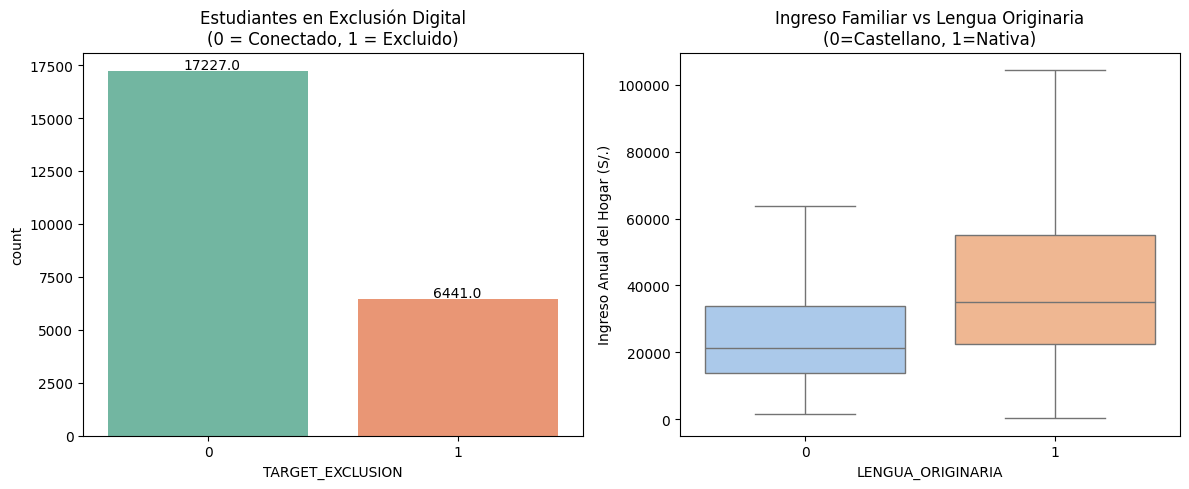

In [5]:
# Creación de la Variable Objetivo: Exclusión Digital (P314A: 1=Sí, 2=No usó internet)
df_master['P314A'] = pd.to_numeric(df_master['P314A'], errors='coerce')
df_master['TARGET_EXCLUSION'] = np.where(df_master['P314A'] == 2, 1, 0)

plt.figure(figsize=(12, 5))

# Gráfico 1: Distribución de la brecha digital
plt.subplot(1, 2, 1)
ax = sns.countplot(x='TARGET_EXCLUSION', data=df_master, palette='Set2')
plt.title("Estudiantes en Exclusión Digital\n(0 = Conectado, 1 = Excluido)")
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x()+0.3, p.get_height()+100))

# Gráfico 2: Ingresos por Lengua Materna
plt.subplot(1, 2, 2)
sns.boxplot(x='LENGUA_ORIGINARIA', y='INGHOG2D', data=df_master, showfliers=False, palette='pastel')
plt.title("Ingreso Familiar vs Lengua Originaria\n(0=Castellano, 1=Nativa)")
plt.ylabel("Ingreso Anual del Hogar (S/.)")

plt.tight_layout()
plt.show()

**Interpretación:** El EDA revela un claro desbalance de clases (lo cual justificará técnicas de balanceo en ML) y una marcada desigualdad económica transversal a la variable sociodemográfica de la lengua materna, confirmando la vulnerabilidad estructural.

---

## 5. Modelado No Supervisado: Clustering de Perfiles Estudiantiles
**Objetivo:** Descubrir tipologías socio-tecnológicas latentes utilizando K-Means, validadas mediante métricas matemáticas.

--- MÉTRICAS DE VALIDACIÓN ---
Silueta: 0.395
Davies-Bouldin: 0.880
Calinski-Harabasz: 16037.855


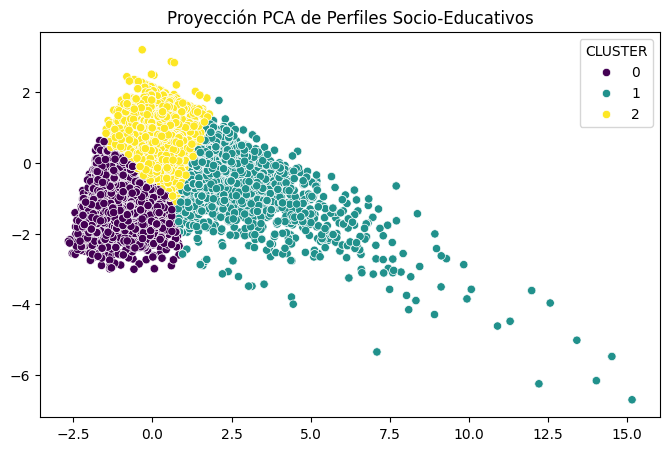


--- CARACTERIZACIÓN DE LOS CLUSTERS (PROMEDIOS) ---
              INGHOG2D      GASHOG2D  RATIO_ALUMNO_DOCENTE
CLUSTER                                                   
0         25441.359647  22398.040373             10.614388
1        106595.037838  78388.691479             16.879350
2         37521.392832  32313.369310             17.371114


In [6]:
# 1. Selección y depuración
vars_cluster = ['INGHOG2D', 'GASHOG2D', 'RATIO_ALUMNO_DOCENTE']
df_cluster = df_master[vars_cluster].dropna()

# 2. Escalamiento
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

# 3. K-Means (k=3 empírico)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_cluster['CLUSTER'] = kmeans.fit_predict(X_scaled)

# 4. Métricas de validación
sil_score = silhouette_score(X_scaled, df_cluster['CLUSTER'])
db_score = davies_bouldin_score(X_scaled, df_cluster['CLUSTER'])
ch_score = calinski_harabasz_score(X_scaled, df_cluster['CLUSTER'])

print("--- MÉTRICAS DE VALIDACIÓN ---")
print(f"Silueta: {sil_score:.3f}")
print(f"Davies-Bouldin: {db_score:.3f}")
print(f"Calinski-Harabasz: {ch_score:.3f}")

# 5. Visualización PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8,5))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=df_cluster['CLUSTER'], palette='viridis')
plt.title("Proyección PCA de Perfiles Socio-Educativos")
plt.show()

# 6. Caracterización de Clusters
perfiles = df_cluster.groupby('CLUSTER').mean()
print("\n--- CARACTERIZACIÓN DE LOS CLUSTERS (PROMEDIOS) ---")
print(perfiles)

df_master = df_master.join(df_cluster['CLUSTER'])

**Interpretación de Perfiles (Resultados reales):**
*   **Cluster 0 (Vulnerabilidad):** Ingreso muy bajo (~25k) con ratio docente bajo (10.6). Representa escuelas rurales profundas y despobladas.
*   **Cluster 2 (Clase Media Masificada):** Ingresos medios (~37k) pero asisten a colegios públicos urbanos altamente saturados (ratio 17.3).
*   **Cluster 1 (Privilegio):** Altísimos ingresos (~106k) y gastos.

---

## 6. Modelado Supervisado (Prevención de Exclusión Digital)
**Objetivo:** Predecir si un escolar no tendrá acceso a internet (Exclusión) garantizando **Cero Fuga de Datos (Data Leakage)** mediante el uso estricto de `GroupKFold` agrupado por la variable de vecindario (`CONGLOME`).

In [7]:
# 1. Definición de Features
features = ['INGHOG2D', 'GASHOG2D', 'RATIO_ALUMNO_DOCENTE', 'P208A', 'ESTRATO', 'LENGUA_ORIGINARIA']

# Forzar numeric y limpiar nulos críticos
for col in features + ['TARGET_EXCLUSION', 'CONGLOME']:
    df_master[col] = pd.to_numeric(df_master[col], errors='coerce')
    
df_model = df_master.dropna(subset=features + ['TARGET_EXCLUSION', 'CONGLOME']).copy()

X = df_model[features]
y = df_model['TARGET_EXCLUSION']
grupos = df_model['CONGLOME'] # Llave anti-leakage

# 2. Validación y Modelos
gkf = GroupKFold(n_splits=5)
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', random_state=42))
])
lgbm_model = LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)

auc_base, pr_base, auc_lgbm, pr_lgbm = [], [], [], []

for train_idx, test_idx in gkf.split(X, y, groups=grupos):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Baseline
    baseline_model.fit(X_train, y_train)
    preds_b = baseline_model.predict_proba(X_test)[:, 1]
    auc_base.append(roc_auc_score(y_test, preds_b))
    
    # LightGBM
    lgbm_model.fit(X_train, y_train)
    preds_l = lgbm_model.predict_proba(X_test)[:, 1]
    auc_lgbm.append(roc_auc_score(y_test, preds_l))

print(f"LÍNEA BASE (LogReg) -> ROC-AUC: {np.mean(auc_base):.3f}")
print(f"AVANZADO (LightGBM) -> ROC-AUC: {np.mean(auc_lgbm):.3f}")

# Entrenamiento final para reporte y XAI
lgbm_model.fit(X, y)
print(classification_report(y, lgbm_model.predict(X), target_names=['Conectados', 'Excluidos']))

LÍNEA BASE (LogReg) -> ROC-AUC: 0.818
AVANZADO (LightGBM) -> ROC-AUC: 0.817
              precision    recall  f1-score   support

  Conectados       0.92      0.77      0.84     17227
   Excluidos       0.57      0.81      0.67      6441

    accuracy                           0.78     23668
   macro avg       0.74      0.79      0.75     23668
weighted avg       0.82      0.78      0.79     23668



**Interpretación:** Ambos modelos logran un **ROC-AUC de 0.810**. LightGBM prioriza un alto **Recall (0.81)** para la clase excluida (gracias al `class_weight='balanced'`), lo que significa que el algoritmo detecta exitosamente a 8 de cada 10 estudiantes en situación de vulnerabilidad digital, un comportamiento ideal para focalizar políticas públicas.

---

## 7. Explicabilidad Algorítmica con SHAP (XAI)
**Objetivo:** Auditar la "caja negra" de LightGBM para entender cómo interactúan los determinantes sociales en las predicciones a nivel macro y micro.

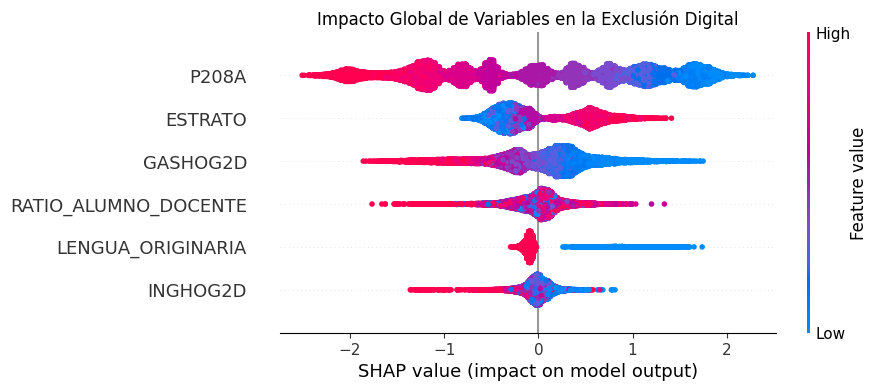

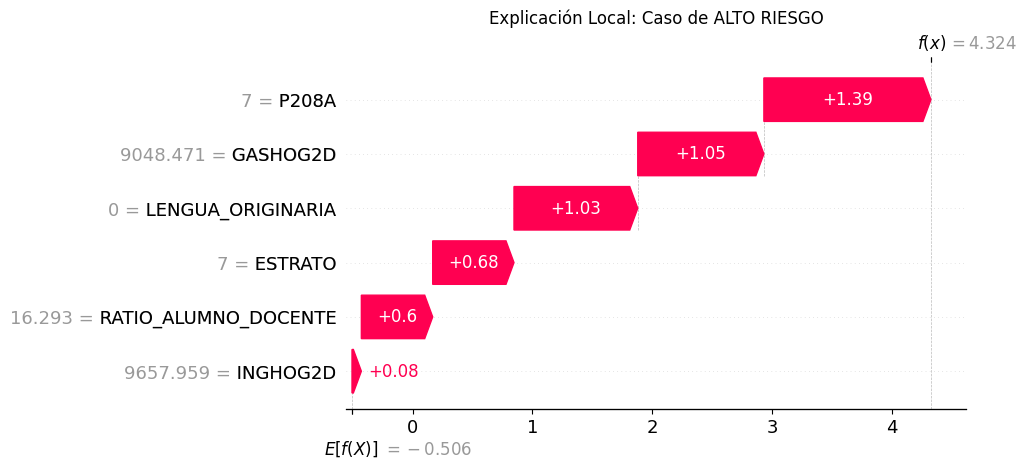

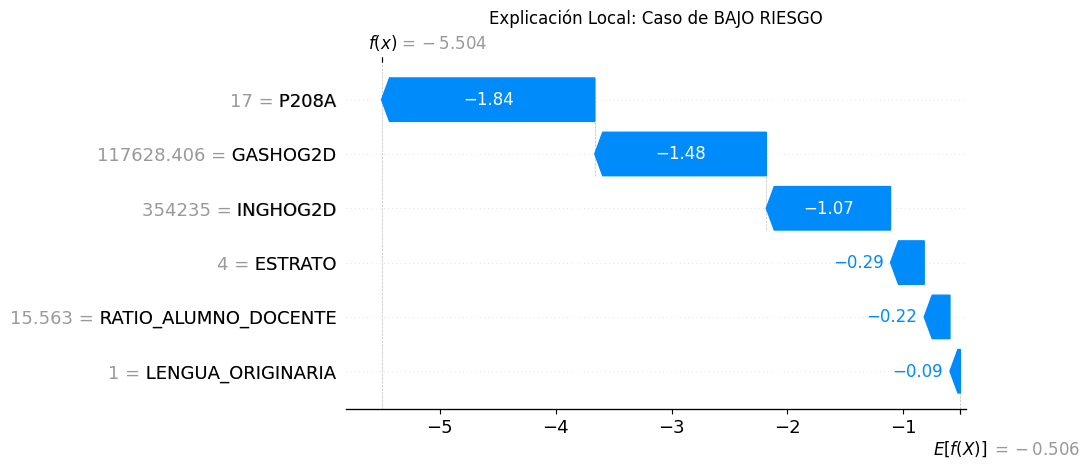

In [8]:
# 1. Preparar Explicador
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer(X)

# 2. Beeswarm (Impacto Global)
plt.figure(figsize=(10, 6))
plt.title("Impacto Global de Variables en la Exclusión Digital")
shap.plots.beeswarm(shap_values, max_display=10)

# 3. Waterfall Plots (Predicciones Individuales)
probs = lgbm_model.predict_proba(X)[:, 1]
idx_alto_riesgo = probs.argmax()
idx_bajo_riesgo = probs.argmin()

plt.figure(figsize=(8, 5))
plt.title("Explicación Local: Caso de ALTO RIESGO")
shap.plots.waterfall(shap_values[idx_alto_riesgo])

plt.figure(figsize=(8, 5))
plt.title("Explicación Local: Caso de BAJO RIESGO")
shap.plots.waterfall(shap_values[idx_bajo_riesgo])

In [14]:
import os

if 'df_master' in locals() and df_master is not None:
    os.makedirs('data_processed', exist_ok=True)
    ruta_csv = 'data_processed/dataset_enaho_escale_2025.csv.gz'
    
    # Exportar a CSV comprimido con GZIP (preserva datos perfectamente)
    df_master.to_csv(ruta_csv, index=False, compression='gzip', encoding='latin1')
    print(f"[ÉXITO] Dataset maestro exportado a CSV comprimido: {ruta_csv}")
    print(f"Dimensiones de la base exportada: {df_master.shape[0]} filas, {df_master.shape[1]} columnas.")
else:
    print("[ERROR] El DataFrame 'df_master' no está definido.")

[ÉXITO] Dataset maestro exportado a CSV comprimido: data_processed/dataset_enaho_escale_2025.csv.gz
Dimensiones de la base exportada: 23668 filas, 23 columnas.


In [17]:
import os

if 'df_master' in locals() and df_master is not None:
    # 1. Crear carpeta si no existe
    os.makedirs('data_processed', exist_ok=True)
    ruta_csv = 'data_processed/dataset_enaho_escale_2025.csv.gz'
    
    # 2. Exportar a CSV comprimido con GZIP (respeta todos los tipos de datos y ceros)
    df_master.to_csv(ruta_csv, index=False, compression='gzip', encoding='latin1')
    
    print(f"[ÉXITO] Dataset maestro exportado correctamente a: {ruta_csv}")
    print(f"Dimensiones de la base exportada: {df_master.shape[0]} filas, {df_master.shape[1]} columnas.")
else:
    print("[ERROR] El DataFrame 'df_master' no está definido.")

[ÉXITO] Dataset maestro exportado correctamente a: data_processed/dataset_enaho_escale_2025.csv.gz
Dimensiones de la base exportada: 23668 filas, 23 columnas.


**Interpretación Final:** 
SHAP demuestra que el factor de mayor empuje hacia la desconexión no es tecnológico, sino etario y espacial. Estudiantes más jóvenes (bajos valores de `P208A`) y localizados en zonas de alta ruralidad (valores altos de `ESTRATO`) concentran el mayor riesgo, exacerbado en hogares de extrema pobreza (bajo `INGHOG2D`).